In [59]:
from __future__ import annotations

from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
import seaborn as sns
import anndata as ad
import scanpy as sc


In [60]:
def gene_cluster_summary(df, meta=None, bystander_genes=None):
    """
    Build a gene-level regulatory-cluster summary directly from a
    long-format significance table (one row per SNP x cell_type, as in
    `sig` / `expecto_sig_vars.csv`), or any filtered subset of it.

    Parameters
    ----------
    df : pd.DataFrame
        Long-format table with columns: SNP, cell_type, z_score,
        gene_name, gene_role. Pre-filter this however you like
        (e.g. df[df['gene_role'] != 'ambiguous']) before passing it in.
    meta : pd.DataFrame, optional
        The variant metadata table (e.g. howSeqweaver_..._RUNFILE.csv),
        used to compute genomic span per gene. If omitted, span_bp and
        pos_min/pos_max are left out of the output.
    bystander_genes : set, optional
        Gene names to exclude as nearest-TSS artifacts.

    Returns
    -------
    pd.DataFrame, one row per gene, sorted by n_variants descending.
    """
    d = df.copy()

    if bystander_genes:
        d = d[~d['gene_name'].isin(bystander_genes)]

    def expected_sign(role):
        if role == 'suppressor':
            return -1
        if role == 'oncogene':
            return 1
        return np.nan

    d['expected_sign'] = d['gene_role'].map(expected_sign)
    d['concordant'] = np.sign(d['z_score']) == d['expected_sign']

    # per-variant collapse first (across cell types)
    per_variant = d.groupby('SNP').agg(
        gene_name=('gene_name', 'first'),
        gene_role=('gene_role', 'first'),
        n_celltypes_sig=('cell_type', 'nunique'),
        max_abs_z=('z_score', lambda x: x.abs().max()),
        pct_concordant=('concordant', 'mean'),
    ).reset_index()

    lead = (
        per_variant.sort_values('max_abs_z', ascending=False)
        .groupby('gene_name')
        .first()[['SNP', 'max_abs_z']]
        .rename(columns={'SNP': 'lead_variant', 'max_abs_z': 'lead_max_abs_z'})
    )

    summary = per_variant.groupby('gene_name').agg(
        gene_role=('gene_role', 'first'),
        n_variants=('SNP', 'nunique'),
        n_celltypes_max=('n_celltypes_sig', 'max'),
        pct_concordant=('pct_concordant', 'mean'),
    )
    summary['pct_concordant'] = (summary['pct_concordant'] * 100).round(0)
    summary = summary.join(lead)

    if meta is not None:
        pos = meta.groupby('gene_name')['snp_chromStart'].agg(pos_min='min', pos_max='max')
        summary = summary.join(pos)
        summary['span_bp'] = summary['pos_max'] - summary['pos_min']
        summary = summary.drop(columns=['pos_min', 'pos_max'])

    cols = ['gene_role', 'n_variants', 'span_bp', 'lead_variant',
            'lead_max_abs_z', 'n_celltypes_max', 'pct_concordant']
    cols = [c for c in cols if c in summary.columns]  # drop span_bp gracefully if no meta

    return summary[cols].sort_values('n_variants', ascending=False)


# usage
"""
BYSTANDER = {'TOE1', 'EPM2AIP1', 'EVI2A', 'NDUFAB1'}
report = gene_cluster_summary(sig, meta=meta_resolved, bystander_genes=BYSTANDER)
report

"""

def plot_gene_cluster_report(report, figsize=None, cmap='RdBu'):
    """
    Horizontal bar chart from a gene_cluster_summary() output: one bar per
    gene, length = n_variants in the cluster, color = % directionally
    concordant with gene role, annotated with the lead variant's z-score.

    Parameters
    ----------
    report : pd.DataFrame
        Output of gene_cluster_summary(), indexed by gene_name.
    """
    df = report.sort_values('n_variants', ascending=True)  # ascending so biggest ends up on top after barh
    n = len(df)
    figsize = figsize or (8, max(3, 0.4 * n))

    fig, ax = plt.subplots(figsize=figsize)

    norm = plt.Normalize(0, 100)
    colors = plt.get_cmap(cmap)(norm(df['pct_concordant'].fillna(50)))

    bars = ax.barh(df.index, df['n_variants'], color=colors, edgecolor='white', height=0.7)

    # annotate: lead variant z-score at the end of each bar
    for bar, (_, row) in zip(bars, df.iterrows()):
        ax.text(
            bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f"z={row['lead_max_abs_z']:.1f}  (n_ct={row['n_celltypes_max']})",
            va='center', fontsize=8, color='dimgrey'
        )

    ax.set_xlabel('Number of variants in cluster')
    ax.set_title('Candidate regulatory clusters by gene', fontsize=12, fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_xlim(0, df['n_variants'].max() * 1.35)  # headroom for annotations

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.02, fraction=0.05)
    cbar.set_label('% concordant with gene role', fontsize=9)

    plt.tight_layout()
    return fig, ax


# usage
"""
fig, ax = plot_gene_cluster_report(report)
plt.show()
"""

'\nfig, ax = plot_gene_cluster_report(report)\nplt.show()\n'

In [61]:

# ------------------------------------------------------------------------
# Load 
# ------------------------------------------------------------------------
scores = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges__breast.csv", index_col='SNP')
scores = scores.drop('macro_mean', axis=1)
meta = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges34_genes_input.RUNFILE.csv")


# ------------------------------------------------------------------------
# Transpose and clean metadata
# ------------------------------------------------------------------------
scores_T = scores.T

adata = ad.AnnData(scores_T)

meta = meta.drop_duplicates()
meta_resolved = meta.sort_values(['SNP', 'dist']).drop_duplicates('SNP', keep='first')

adata.var = pd.merge(adata.var, meta_resolved, on='SNP')
adata.var_names = adata.var['SNP'].values
adata.var_names_make_unique()
adata.obs['cell_type'] = adata.obs.index.astype('category')




/div/pythagoras/u4/eirikhoy/.local/share/uv/python/cpython-3.12.11-linux-x86_64-gnu/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


In [62]:
suppressor = ['ATM', 'BARD1', 'BRCA1', 'BRCA2', 'BRIP1', 'CDH1', 'CHEK2', 'FANCM', 'MEN1', 'MLH1', 'MRE11A', 'MSH2', 
              'MSH6', 'MUTYH', 'NBN', 'NF1', 'PALB2', 'PMS2', 'PTEN', 'RAD50', 'RAD51C', 'RAD51D', 'RECQL', 'STK11', 
              'TP53', 'XRCC2', 'FAM175A/ABRAXAS1', 'GEN1']
onocogene = ['AKT1']


def classify_gene(gene_name):
    if gene_name in suppressor:
        return 'suppressor'
    elif gene_name in onocogene:
        return 'oncogene'
    else:
        return 'ambiguous'

adata.var['gene_role'] = adata.var['gene_name'].apply(classify_gene)
adata.var

,SNP,chrom,snp_chromStart,snp_chromEnd,ref,alt,chrom_gene,tss,tss_chromEnd,strand,gene_name,gene_id,cage_used,dist,gene_role
1_45794979_C_G,1_45794979_C_G,1,45794979,45794980,C,G,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2411,ambiguous
1_45794983_G_A,1_45794983_G_A,1,45794983,45794984,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2415,ambiguous
1_45794993_G_A,1_45794993_G_A,1,45794993,45794994,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2425,ambiguous
1_45794998_G_C,1_45794998_G_C,1,45794998,45794999,G,C,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2430,ambiguous
1_45795002_G_A,1_45795002_G_A,1,45795002,45795003,G,A,1,45792568,45792569,+,HPDL,ENSG00000186603,True,2434,ambiguous
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8_90996799_T_A,8_90996799_T_A,8,90996799,90996800,T,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,72,suppressor
8_90996805_G_A,8_90996805_G_A,8,90996805,90996806,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,66,suppressor
8_90996810_G_A,8_90996810_G_A,8,90996810,90996811,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,61,suppressor
8_90996815_C_T,8_90996815_C_T,8,90996815,90996816,C,T,8,90996871,90996872,-,NBN,ENSG00000104320,True,56,suppressor


In [63]:
# ------------------------------------------------------------------------
# Long-format z-scores: one row per (variant, cell_type)
# ------------------------------------------------------------------------
df = (
    pd.DataFrame(adata.X, index=adata.obs_names, columns=adata.var_names)
    .melt(var_name='SNP', value_name='z_score', ignore_index=False)
    .rename_axis('cell_type')
    .reset_index()
    .merge(adata.var[['gene_name', 'gene_role']], left_on='SNP', right_index=True)
)


<Axes: xlabel='z_score', ylabel='Count'>

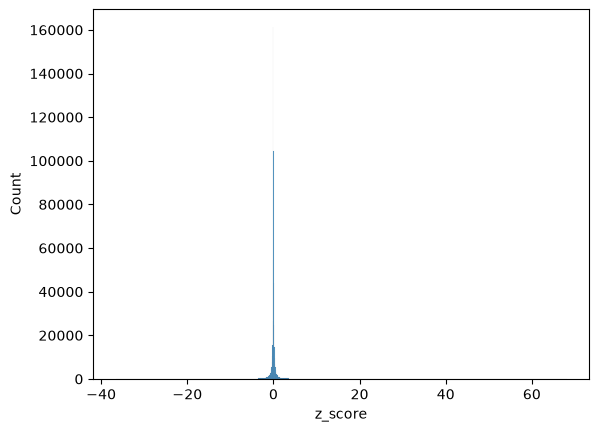

In [64]:
sns.histplot(
    df['z_score']
)

In [ ]:
# Sort df so only those with abs |z-score| > 1 is included
sig = df[abs(df['z_score']) > 1]

# Run the report function on significant z-scores
report = gene_cluster_summary(sig, meta=meta_resolved, bystander_genes=None)
report

,gene_role,n_variants,span_bp,lead_variant,lead_max_abs_z,n_celltypes_max,pct_concordant
gene_name,,,,,,,
MSH2,suppressor,220,29910,2_47630103_C_T,26.071206,58,53.0
MSH6,suppressor,159,10262,2_48026020_C_T,12.866146,58,52.0
PALB2,suppressor,146,19850,16_23652461_C_A,9.838396,58,57.0
EVI2A,ambiguous,136,14842,17_29667528_G_A,11.040633,47,0.0
FANCM,suppressor,115,19666,14_45605454_G_A,36.611392,58,47.0
MLH1,suppressor,106,18733,3_37034997_C_T,24.016506,58,48.0
PMS2,suppressor,97,19239,7_6048640_G_C,12.495001,58,65.0
STK11,suppressor,94,14530,19_1207160_A_G,15.527366,58,34.0
RAD51C,suppressor,91,17478,17_56769964_T_C,12.462017,58,45.0


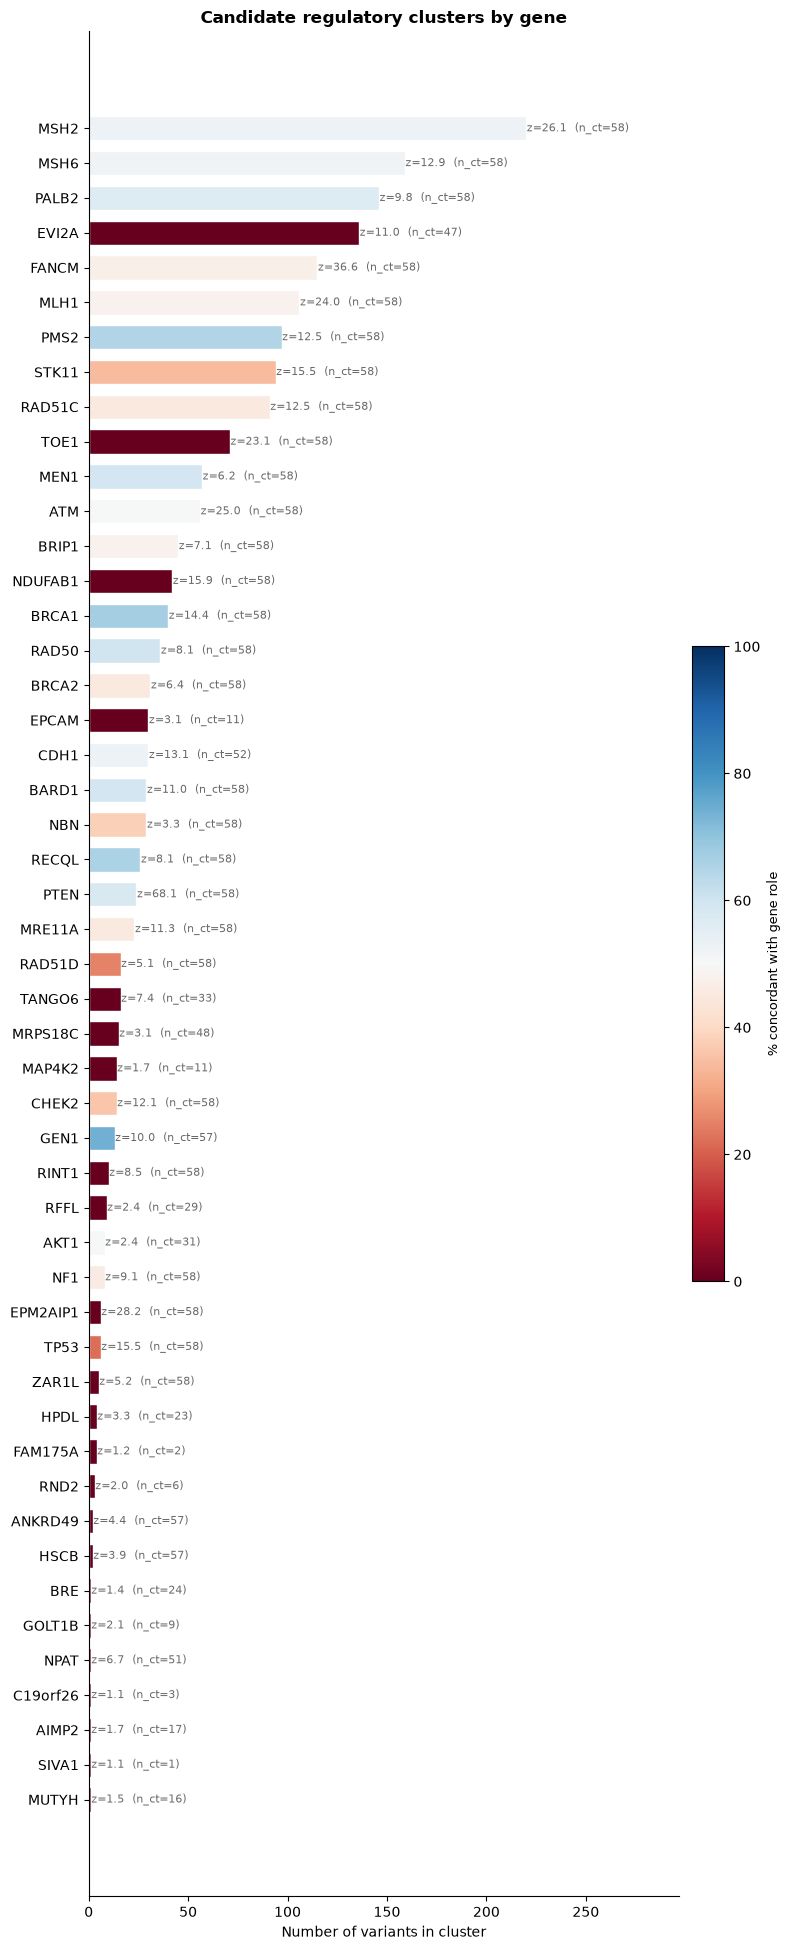

In [ ]:
# Make barplot of number of variants per gene

fig, ax = plot_gene_cluster_report(report)
plt.show()


In [49]:
report = gene_cluster_summary(df, meta=meta_resolved, bystander_genes=None)
report

,gene_role,n_variants,span_bp,lead_variant,lead_max_abs_z,n_celltypes_max,pct_concordant
gene_name,,,,,,,
AP001925.1,ambiguous,887,37567,11_108141990_T_G,0.974468,58,0.0
PALB2,suppressor,836,19850,16_23652461_C_A,9.838396,58,47.0
MSH6,suppressor,831,10262,2_48026020_C_T,12.866146,58,50.0
BRCA2,suppressor,590,17911,13_32889647_A_C,6.444256,58,42.0
MSH2,suppressor,499,29910,2_47630103_C_T,26.071206,58,51.0
HPDL,ambiguous,447,4222,1_45799190_G_A,3.319150,58,0.0
TP53,suppressor,425,17845,17_7590777_T_C,15.485518,58,44.0
PMS2,suppressor,400,19239,7_6048640_G_C,12.495001,58,51.0
EVI2A,ambiguous,370,14842,17_29667528_G_A,11.040633,58,0.0
